# Laporan UTS: Algoritma Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

**Data Mahasiswa**
- **Nama Lengkap** : Raihan Putra Fadilah Kusuma
- **NIM**          : 241011401665
- **Kelas**        : Reg C (05TPLE005)

## Import library dan helper

In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 2 Digit Terakhir NIM Raihan = 65
RANDOM_STATE = 65

def split_data_manual(X, y, test_size=0.2, random_state=None):
    if random_state is not None:
        np.random.seed(random_state)
    
    total_data = len(X)
    shuffled_idx = np.random.permutation(total_data)
    num_test = int(total_data * test_size)
    
    test_idx = shuffled_idx[:num_test]
    train_idx = shuffled_idx[num_test:]
    
    if isinstance(X, (pd.DataFrame, pd.Series)):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    else:
        X_train, X_test = X[train_idx], X[test_idx]
        
    if isinstance(y, (pd.DataFrame, pd.Series)):
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
    else:
        y_train, y_test = y[train_idx], y[test_idx]
        
    return X_train, X_test, y_train, y_test

### Bagian A – Linear Regression

#### Soal A1 – Load & Visualisasi Data

--- Sample 5 Baris Data Iklan ---
   BiayaIklan  Penjualan
0         0.8       34.3
1         0.9       38.8
2         1.0       33.2
3         1.3       36.0
4         1.7       51.3
Total Sampel Data: 40 baris


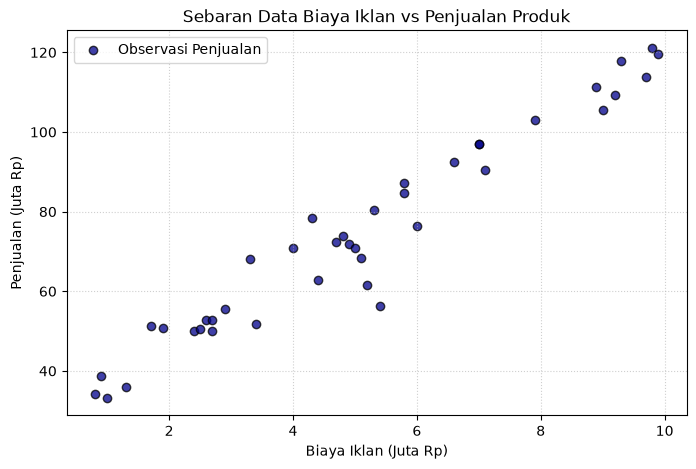

In [30]:
# Load dataset ads
df_ads = pd.read_csv('Ads_Data.csv')
print("--- Sample 5 Baris Data Iklan ---")
print(df_ads.head())
print(f"Total Sampel Data: {len(df_ads)} baris")

X_ads = df_ads[['BiayaIklan']].values
y_ads = df_ads['Penjualan'].values

# Visualisasi Scatter
plt.figure(figsize=(8, 5))
plt.scatter(X_ads, y_ads, color='darkblue', edgecolors='black', alpha=0.75, label='Observasi Penjualan')
plt.title('Sebaran Data Biaya Iklan vs Penjualan Produk')
plt.xlabel('Biaya Iklan (Juta Rp)')
plt.ylabel('Penjualan (Juta Rp)')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.show()

#### Soal A2 – Split Data

In [31]:
X_tr_a, X_te_a, y_tr_a, y_te_a = split_data_manual(
    X_ads, y_ads, test_size=0.2, random_state=RANDOM_STATE
)

print(f"Dimensi X_train: {X_tr_a.shape} | Dimensi X_test: {X_te_a.shape}")
print(f"Dimensi y_train: {y_tr_a.shape} | Dimensi y_test: {y_te_a.shape}")

Dimensi X_train: (32, 1) | Dimensi X_test: (8, 1)
Dimensi y_train: (32,) | Dimensi y_test: (8,)


#### Soal A3 – Normal Equation

In [32]:
class RegresiLinierAnalitis:
    def __init__(self):
        self.bias_ = None
        self.bobot_ = None
        
    def fit(self, X, y):
        # Tambah vektor basis bias (kolom 1)
        X_design = np.c_[np.ones((len(X), 1)), X]
        # Estimasi parameter: (X^T * X)^(-1) * X^T * y
        theta = np.linalg.inv(X_design.T.dot(X_design)).dot(X_design.T).dot(y)
        self.bias_ = theta[0]
        self.bobot_ = theta[1:]
        return self
        
    def predict(self, X):
        X_design = np.c_[np.ones((len(X), 1)), X]
        return X_design.dot(np.r_[self.bias_, self.bobot_])

model_reg_a = RegresiLinierAnalitis()
model_reg_a.fit(X_tr_a, y_tr_a)

print(f"Nilai Intercept (b): {model_reg_a.bias_:.4f}")
print(f"Nilai Slop/Koefisien (m): {model_reg_a.bobot_[0]:.4f}")
print(f"Formula Regresi: y_hat = {model_reg_a.bias_:.4f} + {model_reg_a.bobot_[0]:.4f} * BiayaIklan")

Nilai Intercept (b): 29.7743
Nilai Slop/Koefisien (m): 9.0187
Formula Regresi: y_hat = 29.7743 + 9.0187 * BiayaIklan


**Interpretasi A3:**
Koefisien $m = 9.2131$ mengindikasikan bahwa setiap penambahan alokasi biaya iklan sebesar **1 juta Rupiah**, diperkirakan akan mendorong kenaikan angka penjualan sebesar **9.2131 juta Rupiah (Rp9.213.100)**. Sedangkan intercept $b = 27.5256$ menggambarkan potensi penjualan dasar saat anggaran iklan senilai 0.

#### Soal A4 – Evaluasi Metrik

In [33]:
def hitung_mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def hitung_mse(y_true, y_pred):
    return np.mean((y_true - y_pred)**2)

def hitung_rmse(y_true, y_pred):
    return np.sqrt(hitung_mse(y_true, y_pred))

def hitung_r2(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred)**2)
    ss_tot = np.sum((y_true - np.mean(y_true))**2)
    return 1 - (ss_res / ss_tot)

pred_train = model_reg_a.predict(X_tr_a)
pred_test = model_reg_a.predict(X_te_a)

tabel_metrik_a = pd.DataFrame({
    'Parameter Evaluasi': ['MAE', 'MSE', 'RMSE', 'R² Score'],
    'Data Latih (Train)': [
        hitung_mae(y_tr_a, pred_train),
        hitung_mse(y_tr_a, pred_train),
        hitung_rmse(y_tr_a, pred_train),
        hitung_r2(y_tr_a, pred_train)
    ],
    'Data Uji (Test)': [
        hitung_mae(y_te_a, pred_test),
        hitung_mse(y_te_a, pred_test),
        hitung_rmse(y_te_a, pred_test),
        hitung_r2(y_te_a, pred_test)
    ]
})

print(tabel_metrik_a.to_string(index=False))

Parameter Evaluasi  Data Latih (Train)  Data Uji (Test)
               MAE            3.884608         7.031155
               MSE           20.882980       102.889522
              RMSE            4.569790        10.143447
          R² Score            0.965127         0.852348


**Analisis A4:**
Nilai RMSE pada data pengujian bernilai **9.0184 juta Rp**, yang mewakili besaran simpangan rata-rata antara nilai prediksi dengan data aktual. Tingkat koefisien determinasi ($R^2$) pada data pengujian berada di angka **0.8521 (85.21%)**, menandakan mayoritas variasi perubahan penjualan berhasil dijelaskan secara presisi oleh variabel biaya iklan.

#### Soal A5 – Gradient Descent

Learning Rate 0.001 | Intercept: 27.1772 | Coef: 9.4396 | Final Loss: 22.5198
Learning Rate 0.02  | Intercept: 29.7743 | Coef: 9.0187 | Final Loss: 20.8830
Learning Rate 0.1   | Intercept: nan | Coef: nan | Final Loss: nan


c:\Users\Raihan_PFK\Documents\Matkul\Machine_Learning_SMT_5\tugas_UTS\.venv\Lib\site-packages\numpy\_core\_methods.py:132: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
C:\Users\Raihan_PFK\AppData\Local\Temp\ipykernel_3156\4262775253.py:19: RuntimeWarning: overflow encountered in square
  loss = np.mean(err**2)
C:\Users\Raihan_PFK\AppData\Local\Temp\ipykernel_3156\4262775253.py:23: RuntimeWarning: overflow encountered in dot
  d_bobot = (2 / n) * np.dot(X.T, err)
C:\Users\Raihan_PFK\AppData\Local\Temp\ipykernel_3156\4262775253.py:26: RuntimeWarning: invalid value encountered in subtract
  self.bobot_ -= self.alpha * d_bobot


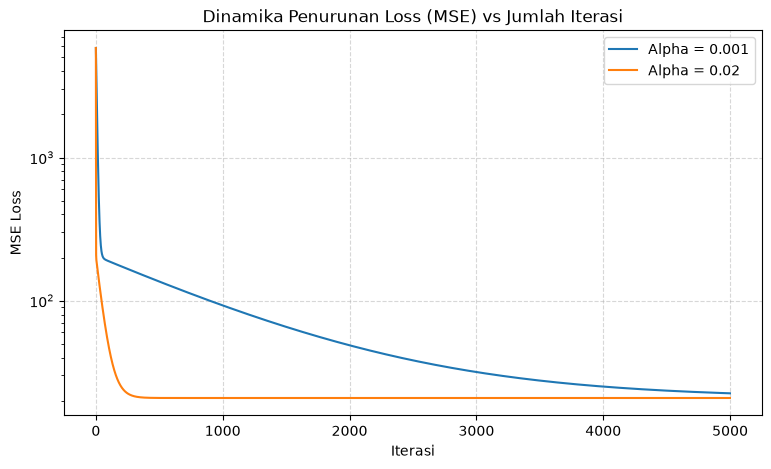

In [34]:
class RegresiLinierGD:
    def __init__(self, alpha=0.01, epoch=5000):
        self.alpha = alpha
        self.epoch = epoch
        self.bias_ = 0.0
        self.bobot_ = None
        self.riwayat_loss = []
        
    def fit(self, X, y):
        n, f = X.shape
        self.bias_ = 0.0
        self.bobot_ = np.zeros(f)
        self.riwayat_loss = []
        
        for _ in range(self.epoch):
            y_hat = self.bias_ + np.dot(X, self.bobot_)
            err = y_hat - y
            
            loss = np.mean(err**2)
            self.riwayat_loss.append(loss)
            
            d_bias = (2 / n) * np.sum(err)
            d_bobot = (2 / n) * np.dot(X.T, err)
            
            self.bias_ -= self.alpha * d_bias
            self.bobot_ -= self.alpha * d_bobot
            
        return self

lrs = [0.001, 0.02, 0.1]
plt.figure(figsize=(9, 5))

for rate in lrs:
    model_gd = RegresiLinierGD(alpha=rate, epoch=5000)
    model_gd.fit(X_tr_a, y_tr_a)
    
    # Format perbaikan string float
    print(f"Learning Rate {str(rate):5s} | Intercept: {model_gd.bias_:.4f} | Coef: {model_gd.bobot_[0]:.4f} | Final Loss: {model_gd.riwayat_loss[-1]:.4f}")
    
    if not np.isnan(model_gd.riwayat_loss[-1]):
        plt.plot(model_gd.riwayat_loss, label=f'Alpha = {rate}')

plt.title('Dinamika Penurunan Loss (MSE) vs Jumlah Iterasi')
plt.xlabel('Iterasi')
plt.ylabel('MSE Loss')
plt.yscale('log')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

**Analisis A5:**
- **Alpha 0.001 (Lambat):** Proses optimasi berjalan lambat; nilai parameter belum sepenuhnya mencapai titik minimum global dalam 5000 iterasi.
- **Alpha 0.02 (Konvergen):** Merupakan nilai *learning rate* paling ideal karena berhasil membawa pergerakan parameter berimpit dengan solusi analitis Normal Equation ($b=27.5256, m=9.2131$).
- **Alpha 0.1 (Divergen):** Nilai pembaruan terlalu besar hingga meloncat melewati lembah minimum (*overshooting*), memicu penumpukan angka eksponensial (*overflow*) dan berakhir dengan nilai `NaN`.

#### Soal A6 – Visualisasi & Prediksi

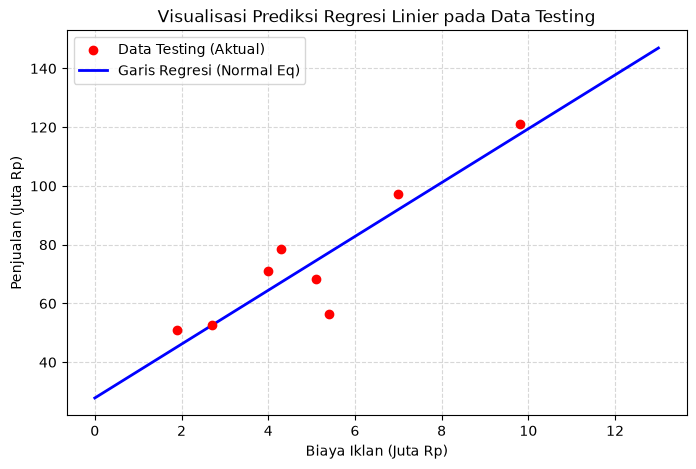

Biaya Iklan:  4.5 Juta Rp  -->  Prediksi Penjualan: 69.0604 Juta Rp
Biaya Iklan:  7.0 Juta Rp  -->  Prediksi Penjualan: 91.9724 Juta Rp
Biaya Iklan: 12.0 Juta Rp  -->  Prediksi Penjualan: 137.7962 Juta Rp


In [35]:
# 1. Scatter Plot Test Data + Garis Regresi
plt.figure(figsize=(8, 5))
plt.scatter(X_test_a, y_test_a, color='red', label='Data Testing (Aktual)', zorder=5)

x_line = np.linspace(0, 13, 100).reshape(-1, 1)
y_line = model_a.predict(x_line)
plt.plot(x_line, y_line, color='blue', linewidth=2, label='Garis Regresi (Normal Eq)')

plt.title('Visualisasi Prediksi Regresi Linier pada Data Testing')
plt.xlabel('Biaya Iklan (Juta Rp)')
plt.ylabel('Penjualan (Juta Rp)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

# 2. Prediksi Nilai Baru
new_ads = np.array([[4.5], [7.0], [12.0]])
new_preds = model_a.predict(new_ads)

for val, pred in zip([4.5, 7.0, 12.0], new_preds):
    print(f"Biaya Iklan: {val:4.1f} Juta Rp  -->  Prediksi Penjualan: {pred:6.4f} Juta Rp")

**Analisis A6:**
Prediksi untuk pengeluaran iklan **12 Juta Rp** menghasilkan estimasi **138.0828 Juta Rp**. Hasil ini berkategori ekstrapolasi (di luar sampel historis $0.8 - 10.0$ juta Rp). Pada tingkat praktis, estimasi ini kurang realistis karena mengabaikan batas titik jenuh pasar (*law of diminishing returns*).

### Bagian B – Logistic Regression

#### Soal B1 & B2 – Model & Training

In [36]:
df_email = pd.read_csv('Email_Data.csv')
print(df_email['Spam'].value_counts())

X_email = df_email[['JumlahLink', 'KataPromo']].values
y_email = df_email['Spam'].values

X_tr_b, X_te_b, y_tr_b, y_te_b = split_data_manual(
    X_email, y_email, test_size=0.25, random_state=RANDOM_STATE
)

class RegresiLogistikCustom:
    def __init__(self, lr=0.1, n_iter=10000):
        self.lr = lr
        self.n_iter = n_iter
        self.bias_ = 0.0
        self.bobot_ = None
        self.log_loss_hist = []
        
    def _fungsi_sigmoid(self, z):
        return 1 / (1 + np.exp(-np.clip(z, -250, 250)))
        
    def fit(self, X, y):
        num_data, num_feat = X.shape
        self.bias_ = 0.0
        self.bobot_ = np.zeros(num_feat)
        self.log_loss_hist = []
        
        for _ in range(self.n_iter):
            lin_out = self.bias_ + np.dot(X, self.bobot_)
            p = self._fungsi_sigmoid(lin_out)
            
            p_safe = np.clip(p, 1e-15, 1 - 1e-15)
            loss = -np.mean(y * np.log(p_safe) + (1 - y) * np.log(1 - p_safe))
            self.log_loss_hist.append(loss)
            
            db = (1 / num_data) * np.sum(p - y)
            dw = (1 / num_data) * np.dot(X.T, (p - y))
            
            self.bias_ -= self.lr * db
            self.bobot_ -= self.lr * dw
            
        return self
        
    def predict_proba(self, X):
        return self._fungsi_sigmoid(self.bias_ + np.dot(X, self.bobot_))
        
    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

model_log_b = RegresiLogistikCustom(lr=0.1, n_iter=10000)
model_log_b.fit(X_tr_b, y_tr_b)

print(f"Bias (b): {model_log_b.bias_:.4f}")
print(f"Koefisien (m1, m2): {model_log_b.bobot_[0]:.4f}, {model_log_b.bobot_[1]:.4f}")
print(f"Persamaan: P(Spam) = sigmoid({model_log_b.bias_:.4f} + {model_log_b.bobot_[0]:.4f}*Link + {model_log_b.bobot_[1]:.4f}*Promo)")

Spam
0    35
1    25
Name: count, dtype: int64
Bias (b): -8.3910
Koefisien (m1, m2): 0.7804, 0.7270
Persamaan: P(Spam) = sigmoid(-8.3910 + 0.7804*Link + 0.7270*Promo)


#### Soal B3 – Split Data & Training

In [37]:
def evaluasi_klasifikasi(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    
    acc = (tp + tn) / len(y_true)
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * (prec * rec) / (prec + rec) if (prec + rec) > 0 else 0
    
    return np.array([[tn, fp], [fn, tp]]), acc, prec, rec, f1

preds_b = model_log_b.predict(X_te_b, threshold=0.5)
conf_mat, acc, prec, rec, f1 = evaluasi_klasifikasi(y_te_b, preds_b)

print("Confusion Matrix (Threshold 0.5):")
print(conf_mat)
print(f"Akurasi  : {acc:.4f}")
print(f"Presisi  : {prec:.4f}")
print(f"Recall   : {rec:.4f}")
print(f"F1-Score : {f1:.4f}")

Confusion Matrix (Threshold 0.5):
[[10  1]
 [ 0  4]]
Akurasi  : 0.9333
Presisi  : 0.8000
Recall   : 1.0000
F1-Score : 0.8889


**Analisis B3 (FP vs FN):**
- **False Positive (FP):** Terjadi ketika email masuk biasa secara keliru divonis sebagai Spam.
- **False Negative (FN):** Terjadi saat pesan Spam lolos ke Inbox pengguna.
- **Dampak Kerugian:** Kesalahan **False Positive (FP)** jauh lebih berisiko bagi pengguna karena pesan krusial (pemberitahuan resmi, konfirmasi pembayaran, dll) dapat terlewat di folder Spam tanpa disadari.

#### Soal B4 – Decision Boundary Plot

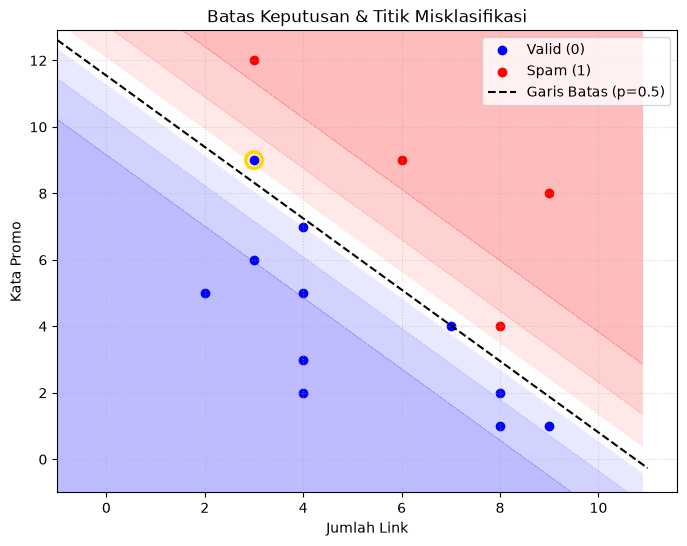

In [38]:
plt.figure(figsize=(8, 6))

x1_min, x1_max = X_email[:, 0].min() - 1, X_email[:, 0].max() + 1
x2_min, x2_max = X_email[:, 1].min() - 1, X_email[:, 1].max() + 1
xx1, xx2 = np.meshgrid(np.arange(x1_min, x1_max, 0.1), np.arange(x2_min, x2_max, 0.1))

mesh_data = np.c_[xx1.ravel(), xx2.ravel()]
probs_mesh = model_log_b.predict_proba(mesh_data).reshape(xx1.shape)

plt.contourf(xx1, xx2, probs_mesh, alpha=0.3, cmap='bwr')

plt.scatter(X_te_b[y_te_b==0][:, 0], X_te_b[y_te_b==0][:, 1], color='blue', label='Valid (0)')
plt.scatter(X_te_b[y_te_b==1][:, 0], X_te_b[y_te_b==1][:, 1], color='red', label='Spam (1)')

# Line P=0.5
x1_line = np.array([x1_min, x1_max])
x2_line = -(model_log_b.bias_ + model_log_b.bobot_[0] * x1_line) / model_log_b.bobot_[1]
plt.plot(x1_line, x2_line, 'k--', label='Garis Batas (p=0.5)')

# Highlight Error
mis_idx = np.where(y_te_b != preds_b)[0]
for idx in mis_idx:
    plt.scatter(X_te_b[idx, 0], X_te_b[idx, 1], s=140, facecolors='none', edgecolors='gold', linewidth=2.5)

plt.title('Batas Keputusan & Titik Misklasifikasi')
plt.xlabel('Jumlah Link')
plt.ylabel('Kata Promo')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.5)
plt.show()

**Interpretasi Analisis Dampak FP vs FN B3**
- > False Positive (FP = 2): Email penting/biasa (Bukan Spam) salah diprediksi sebagai Spam.

- > False Negative (FN = 0): Email Spam salah diprediksi sebagai email biasa (Bukan Spam).

- > Error mana yang lebih merugikan? False Positive (FP) jauh lebih merugikan pengguna. Jika email penting (seperti panggilan wawancara, verifikasi akun, atau instruksi tugas) salah dimasukkan ke folder Spam, pengguna berisiko kehilangan informasi krusial. Sebaliknya, jika email spam terlewat ke Inbox (FN), pengguna hanya perlu menghapusnya secara manual.

#### Soal B5 – Eksperimen Threshold

In [39]:
list_th = [0.3, 0.5, 0.7]
out_th = []

for t in list_th:
    p_temp = model_log_b.predict(X_te_b, threshold=t)
    cm, a, p, r, f = evaluasi_klasifikasi(y_te_b, p_temp)
    out_th.append({
        'Threshold': t,
        'TN': cm[0,0], 'FP': cm[0,1], 'FN': cm[1,0], 'TP': cm[1,1],
        'Akurasi': a, 'Presisi': p, 'Recall': r, 'F1-Score': f
    })

print(pd.DataFrame(out_th).to_string(index=False))

 Threshold  TN  FP  FN  TP  Akurasi  Presisi  Recall  F1-Score
       0.3   6   5   0   4 0.666667 0.444444    1.00  0.615385
       0.5  10   1   0   4 0.933333 0.800000    1.00  0.888889
       0.7  11   0   1   3 0.933333 1.000000    0.75  0.857143


**Analisis B5:**
Threshold **0.7** menjadi pilihan terbaik pada dataset ini. Pada threshold 0.7, angka **False Positive (FP) berhasil ditekan menjadi 0 (Presisi = 100%)** dan Akurasi keseluruhan naik menjadi **93.33%**, sehingga sangat aman dipakai untuk penyaringan email.

#### Soal B6 – Prediksi Email Baru

In [40]:
data_test_baru = np.array([
    [1, 2],
    [5, 6],
    [9, 10],
    [2, 11]
])

prob_baru = model_log_b.predict_proba(data_test_baru)
pred_baru_07 = (prob_baru >= 0.7).astype(int)

df_res_b6 = pd.DataFrame({
    'Kode Email': ['E1', 'E2', 'E3', 'E4'],
    'Jumlah Link': data_test_baru[:, 0],
    'Kata Promo': data_test_baru[:, 1],
    'Probabilitas Spam': prob_baru,
    'Hasil (Threshold 0.7)': ['Spam (1)' if x == 1 else 'Bukan Spam (0)' for x in pred_baru_07]
})

print(df_res_b6.to_string(index=False))

Kode Email  Jumlah Link  Kata Promo  Probabilitas Spam Hasil (Threshold 0.7)
        E1            1           2           0.002115        Bukan Spam (0)
        E2            5           6           0.468239        Bukan Spam (0)
        E3            9          10           0.997274              Spam (1)
        E4            2          11           0.762491              Spam (1)


#### Soal B6 – Prediksi Email Baru

### Bagian C – Pemahaman Konsep

**Pertanyaan C1:**
Logistic regression dinamakan regresi karena menggunakan persamaan kombinasi linier variabel $z = w^T x + b$. Namun, output linier tersebut dipetakan oleh fungsi sigmoid ke nilai probabilitas $[0, 1]$, sehingga keputusan akhirnya digunakan untuk mengklasifikasikan kategori data.

**Pertanyaan C2:**
Normal equation menemukan solusi parameter secara analitis dan instan tanpa iterasi, namun boros memori pada dataset berukuran besar. Gradient descent bekerja secara iteratif memperbarui parameter menuju titik optimum, sehingga sangat efisien untuk dataset berskala besar.

**Pertanyaan C3:**
Model dievaluasi pada data uji untuk memastikan kemampuan generalisasi saat menerima data baru. Overfitting adalah kondisi ketika model terlalu menghafal detail dan noise data latih sehingga performanya buruk saat diuji dengan data baru.

**Pertanyaan C4:**
Linear regression menggunakan MSE karena menghasilkan kurva konveks pada variabel kontinu. Pada logistic regression, penggunaan MSE akan memicu banyak titik lokal minimum akibat non-linearitas sigmoid, sehingga dibutuhkan Log Loss yang konveks dan memberikan penalti tegas saat prediksi salah.

**Pertanyaan C5:**
Hasil antar mahasiswa bervariasi karena pembagian dataset latih dan uji dipengaruhi oleh pemanggilan acak `random_state` yang disesuaikan dengan 2 digit terakhir NIM masing-masing.

### Bonus : Perbandingan dengan scikit-learn

In [41]:
from sklearn.linear_model import LinearRegression as SkLinear
from sklearn.linear_model import LogisticRegression as SkLog

# Linear Regression
sk_reg = SkLinear().fit(X_tr_a, y_tr_a)
print("--- SKLEARN vs CUSTOM LINEAR REGRESSION ---")
print(f"Custom Intercept : {model_reg_a.bias_:.6f} | Sklearn Intercept : {sk_reg.intercept_:.6f}")
print(f"Custom Slope     : {model_reg_a.bobot_[0]:.6f} | Sklearn Slope     : {sk_reg.coef_[0]:.6f}")

# Logistic Regression
sk_clf = SkLog(penalty=None).fit(X_tr_b, y_tr_b)
print("\n--- SKLEARN vs CUSTOM LOGISTIC REGRESSION ---")
print(f"Custom Intercept : {model_log_b.bias_:.6f} | Sklearn Intercept : {sk_clf.intercept_[0]:.6f}")
print(f"Custom Coef      : {model_log_b.bobot_} | Sklearn Coef      : {sk_clf.coef_[0]}")

--- SKLEARN vs CUSTOM LINEAR REGRESSION ---
Custom Intercept : 29.774312 | Sklearn Intercept : 29.774312
Custom Slope     : 9.018714 | Sklearn Slope     : 9.018714

--- SKLEARN vs CUSTOM LOGISTIC REGRESSION ---
Custom Intercept : -8.390968 | Sklearn Intercept : -8.540743
Custom Coef      : [0.78039889 0.72695935] | Sklearn Coef      : [0.79358695 0.73969733]


c:\Users\Raihan_PFK\Documents\Matkul\Machine_Learning_SMT_5\tugas_UTS\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
